# 03 · Challenge 3 — functional integration: germ and soma from one composition

**Review claims (Bozdag et al., Fig. 4, "Challenge 3", "Future directions"):**
1. *Temporal-to-spatial transition* — cell types arise by redeploying, in space, states the unicellular
   ancestor already entered over time in response to the environment (RLS1 → *regA* in volvocine algae).
2. Environmental induction can be an intermediate step (*Eudorina*: soma-like cells under cold stress),
   later brought under developmental control.
3. *Clonality* makes reproductive altruism stable; chimeric groups invite cheaters.
4. Bigger bodies mean most cells no longer touch the environment, so internal gradients appear, and the
   cost of reproductive specialisation falls with size.
5. *Obligate* multicellularity protects multicellular adaptations from counter-selection during a
   unicellular phase (facultative life cycles).

**Model.** Same chemistry (now $N=20$), with one environmental input: the supply of a nutrient-sensing
species $q$ scales with the local nutrient $u$ ($\Lambda_q=u$). $q$ is the sole repressor of a "stress"
species $r$. When $u$ falls, $q$ drops below its binder threshold, $r$ is released, switches on and
represses $q$ — a bistable, environmentally induced cell state (the RLS1 role). Cells with $r$ on
**stop dividing** but **power group survival** (motility/protection): soma. The genetic parameter
$\theta = \Lambda_r$ (catalytic efficiency of the $r$ reaction) sets the nutrient level that flips the switch.

In a group, nutrient diffuses in from the surface and is consumed, so interior cells see less of it
(steady-state diffusion–consumption profile in a sphere). The *same* switch can therefore be triggered
by position instead of by time. Group fitness at maturity: $W = n_\text{germ}\,S(f_\text{soma})$, with
$S$ increasing and saturating.

Run time: ~8–12 min on a 4-core laptop (`FAST = True`: ~4 min).

In [1]:
import os, time, numpy as np, matplotlib.pyplot as plt
from protoevo import run_parallel
import nb3_model as m3
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FAST = False
N_JOBS = None
GENS = 40 if FAST else 70
THETA_ANC = 0.55
t_start = time.time()
chem, anc, roles = m3.setup()
r, q = roles['r'], roles['q']
print('nutrient sensor q =', q, '| stress species r =', r, '| ancestral P =', chem.state(anc).mean())

nutrient sensor q = 5 | stress species r = 2 | ancestral P = 0.4


## A · The unicellular ancestor: a temporal, environmentally induced cell state
Left: probability that a single cell is in the $r$-on state after 20 time units at nutrient $u$, for
several $\theta$ — a switch-like reaction norm whose threshold the genotype tunes.
Right: in a fluctuating environment the ancestor ($\theta=0.55$) enters and leaves the stress state over time.

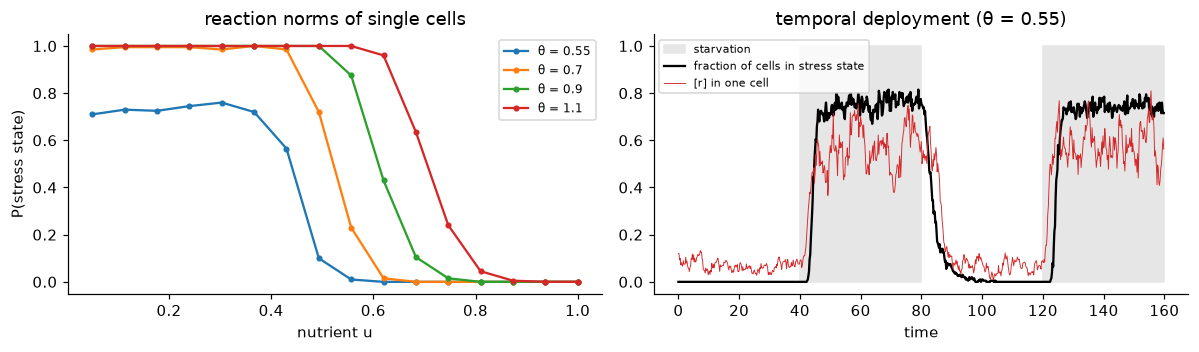

In [2]:
u_grid = np.linspace(0.05, 1.0, 16)
thetas = [0.55, 0.7, 0.9, 1.1]
norms = {th: m3.reaction_norm(chem, anc, roles, u_grid, th, n_cells=100 if FAST else 200, T=20) for th in thetas}
rng = np.random.default_rng(0)
nC, T = 200, 160
X = np.tile(anc, (nC, 1)); fr, ut, traces = [], [], []
for k in range(int(T / chem.dt)):
    t = k * chem.dt
    u = 1.0 if (t // 40) % 2 == 0 else 0.25
    X = chem.step(X, rng, Lam=m3.lam_matrix(chem, roles, np.full(nC, u), THETA_ANC))
    if k % 10 == 0:
        fr.append((X[:, r] > 0.5).mean()); ut.append(u); traces.append(X[:4, r].copy())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for th in thetas: ax[0].plot(u_grid, norms[th], 'o-', ms=3, label=f'θ = {th}')
ax[0].set_xlabel('nutrient u'); ax[0].set_ylabel('P(stress state)'); ax[0].legend(fontsize=8)
ax[0].set_title('reaction norms of single cells')
tt = np.arange(len(fr)) * 10 * chem.dt
ax[1].fill_between(tt, 0, 1, where=np.array(ut) < 0.5, color='0.9', label='starvation')
ax[1].plot(tt, fr, c='k', label='fraction of cells in stress state')
ax[1].plot(tt, np.array(traces)[:, 0], c='tab:red', lw=.6, label='[r] in one cell')
ax[1].set_xlabel('time'); ax[1].legend(fontsize=7, loc='upper left'); ax[1].set_title('temporal deployment (θ = 0.55)')
plt.tight_layout(); plt.savefig('figures/03_unicell.png'); plt.show()

## B · The same switch in a group: spatial deployment
Clonal groups develop from one cell to ~32 cells. With the ancestral $\theta$, groups make soma only when
the *external* environment is poor (environmental induction, the *Eudorina* intermediate). With a higher
$\theta$, the interior cells — starved by their neighbours' consumption — switch even in a rich
environment: a spatial pattern without any new chemistry.

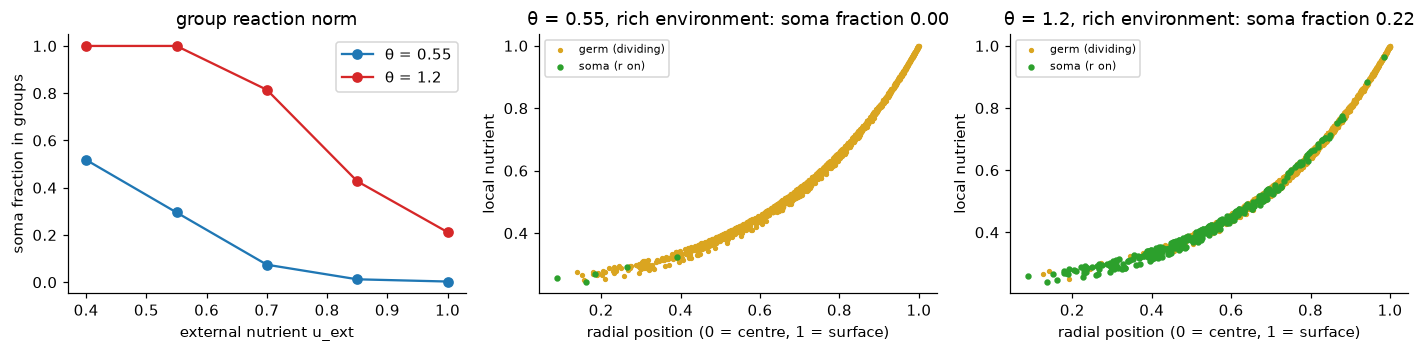

In [3]:
def develop_groups(theta, u_ext, n=60, seed=0, mu=0.0):
    rng = np.random.default_rng(seed)
    return m3.develop(chem, roles, np.tile(anc, (n, 1)), np.full(n, theta), np.arange(n), rng,
                      u_ext=u_ext, mu=mu)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for th, c in [(THETA_ANC, 'tab:blue'), (1.2, 'tab:red')]:
    fs = []
    for ue in [0.4, 0.55, 0.7, 0.85, 1.0]:
        col = develop_groups(th, ue, n=40)
        fs.append(col.traits['soma'].mean())
    ax[0].plot([0.4, 0.55, 0.7, 0.85, 1.0], fs, 'o-', c=c, label=f'θ = {th}')
ax[0].set_xlabel('external nutrient u_ext'); ax[0].set_ylabel('soma fraction in groups'); ax[0].legend()
ax[0].set_title('group reaction norm')
for a, th in zip(ax[1:], [THETA_ANC, 1.2]):
    col = develop_groups(th, 1.0, n=40, seed=1)
    size = col.group_sizes()[0]
    depth = col.traits['q'] ** (1 / 3)
    uloc = m3.nutrient_profile(col.traits['q'], size, 1.0)
    soma = col.traits['soma']
    a.scatter(depth[~soma], uloc[~soma], s=6, c='goldenrod', label='germ (dividing)')
    a.scatter(depth[soma], uloc[soma], s=10, c='tab:green', label='soma (r on)')
    a.set_xlabel('radial position (0 = centre, 1 = surface)'); a.set_ylabel('local nutrient')
    a.set_title(f'θ = {th}, rich environment: soma fraction {soma.mean():.2f}'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig('figures/03_spatial.png'); plt.show()

## C · The division-of-labour landscape
Group fitness for fixed genotypes (no mutation): too little soma and the group lacks motility/protection,
too much and too few cells reproduce. The interior cells are nutrient-limited anyway, so making them soma
is cheap — the cost of specialisation falls with size.

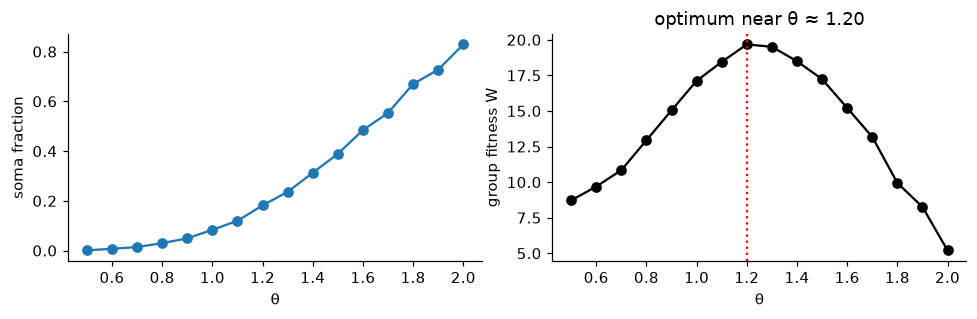

In [4]:
th_grid = np.linspace(0.5, 2.0, 11 if FAST else 16)
fsoma, Wg = [], []
for th in th_grid:
    col = develop_groups(th, 1.0, n=60, seed=2)
    size, gids, cnt, inv = col.group_sizes()
    f = np.bincount(inv, col.traits['soma'].astype(float)) / cnt
    fsoma.append(f.mean()); Wg.append(np.mean(cnt * (1 - f) * m3.survival(f)))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(th_grid, fsoma, 'o-'); ax[0].set_xlabel('θ'); ax[0].set_ylabel('soma fraction')
ax[1].plot(th_grid, Wg, 'o-', c='k'); ax[1].set_xlabel('θ'); ax[1].set_ylabel('group fitness W')
th_opt = th_grid[np.argmax(Wg)]; ax[1].axvline(th_opt, ls=':', c='r')
ax[1].set_title(f'optimum near θ ≈ {th_opt:.2f}'); plt.tight_layout()
plt.savefig('figures/03_landscape.png'); plt.show()

## D · Evolution: clonal versus chimeric development
$\theta$ mutates at 10% of divisions (±0.08). Each generation: groups develop until they are mature (two
time units after reaching 32 cells), are scored ($W$), and release uncommitted germ cells as propagules,
which spend a short dispersal phase in the external medium before founding the next groups.
* **clonal** — each new group starts from one germ cell (kin groups);
* **chimeric** — each new group aggregates 4 germ cells from different parent groups.

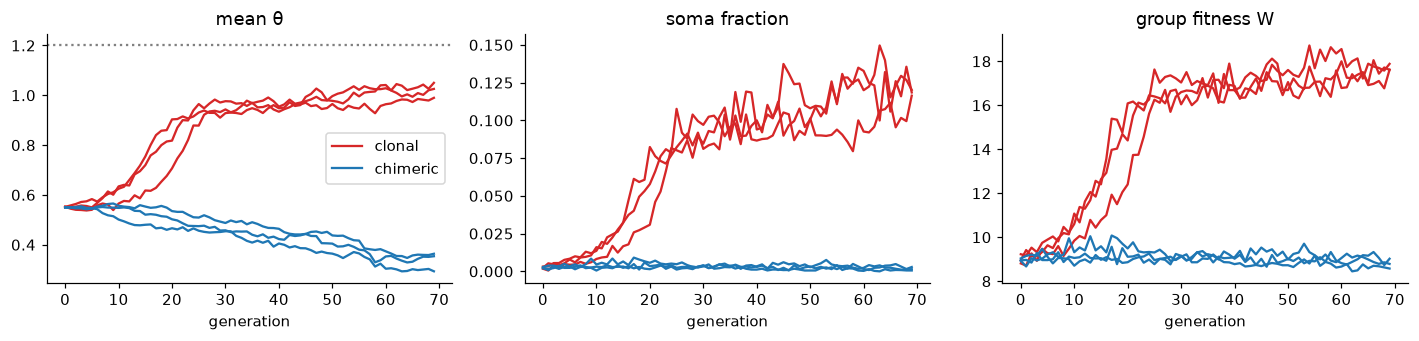

In [5]:
jobs = [dict(gens=GENS, mode=mode, theta0=THETA_ANC, seed=s) for mode in ['clonal', 'chimeric'] for s in range(2 if FAST else 3)]
out = run_parallel(m3.evolve_job, jobs, N_JOBS)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for j, h in zip(jobs, out):
    c = 'tab:red' if j['mode'] == 'clonal' else 'tab:blue'
    ax[0].plot(h['theta'], c=c); ax[1].plot(h['f_soma'], c=c); ax[2].plot(h['W'], c=c)
for a, t in zip(ax, ['mean θ', 'soma fraction', 'group fitness W']): a.set_title(t); a.set_xlabel('generation')
ax[0].axhline(th_opt, ls=':', c='gray')
ax[0].plot([], [], c='tab:red', label='clonal'); ax[0].plot([], [], c='tab:blue', label='chimeric'); ax[0].legend()
plt.tight_layout(); plt.savefig('figures/03_evolution.png'); plt.show()

### Cheaters invade an established division of labour
Take the evolved clonal population and continue it either clonally or with chimeric development.
In chimeras, low-$\theta$ cells stay germ while their partners become soma; they leave more propagules,
and the soma fraction erodes.

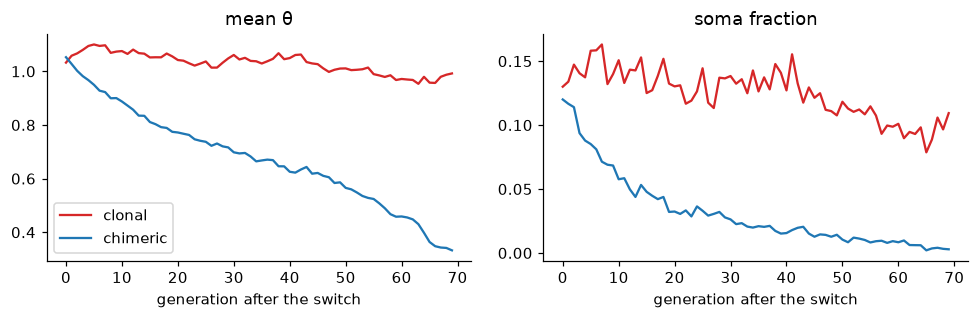

In [6]:
best = max([h for j, h in zip(jobs, out) if j['mode'] == 'clonal'], key=lambda h: h['W'][-10:].mean())
pop = np.random.default_rng(9).normal(best['theta'][-1], best['theta_sd'][-1], 400)
jobs2 = [dict(gens=GENS, mode=mode, theta0=pop, seed=20) for mode in ['clonal', 'chimeric']]
out2 = run_parallel(m3.evolve_job, jobs2, N_JOBS)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for j, h in zip(jobs2, out2):
    c = 'tab:red' if j['mode'] == 'clonal' else 'tab:blue'
    ax[0].plot(h['theta'], c=c, label=j['mode']); ax[1].plot(h['f_soma'], c=c)
ax[0].set_title('mean θ'); ax[1].set_title('soma fraction'); ax[0].legend()
for a in ax: a.set_xlabel('generation after the switch')
plt.tight_layout(); plt.savefig('figures/03_cheaters.png'); plt.show()

## E · From environmental induction to developmental control
Compare the ancestral and evolved (clonal) genotypes. Single cells of both still enter the stress state
only when the environment is poor — the unicellular, temporal program is intact. But groups of the
evolved genotype now differentiate soma in a rich environment: the program is deployed in space, cued
by the group's own geometry.

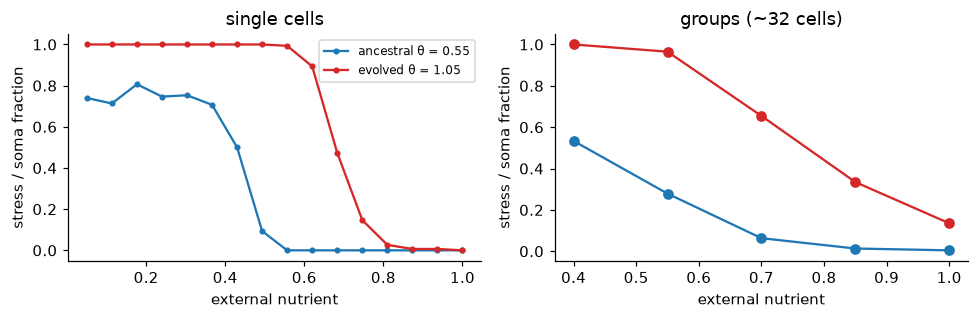

In [7]:
th_evo = best['theta'][-1]
u_ext = [0.4, 0.55, 0.7, 0.85, 1.0]
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for th, c, lab in [(THETA_ANC, 'tab:blue', 'ancestral'), (th_evo, 'tab:red', 'evolved')]:
    ax[0].plot(u_grid, m3.reaction_norm(chem, anc, roles, u_grid, th, n_cells=150, T=20), 'o-', ms=3, c=c, label=f'{lab} θ = {th:.2f}')
    ax[1].plot(u_ext, [develop_groups(th, ue, n=40, seed=3).traits['soma'].mean() for ue in u_ext], 'o-', c=c)
ax[0].set_title('single cells'); ax[1].set_title('groups (~32 cells)')
for a in ax: a.set_xlabel('external nutrient'); a.set_ylabel('stress / soma fraction')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig('figures/03_assimilation.png'); plt.show()

## F · Facultative versus obligate multicellularity
Start from the evolved clonal population (division of labour established) and insert $U$ rounds of
free-living unicellular growth (mildly poor environment, $u=0.45$) between group generations. There,
the same high-$\theta$ allele that makes good soma in groups makes a lone cell quiescent — it is
counter-selected in the unicellular phase, so the multicellular adaptation erodes, faster for longer
unicellular phases (cf. Peterson et al. 2026, ref. 101 of the review).

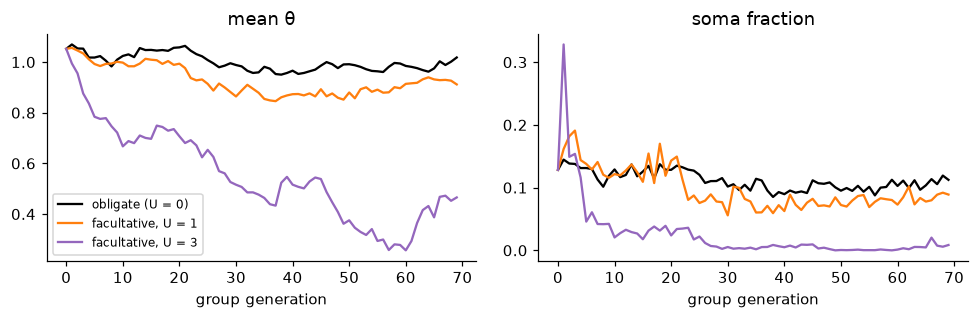

total run time: 264 s


In [8]:
Us = [0, 1, 3]
jobs3 = [dict(gens=GENS, mode='clonal', theta0=pop, U=U, seed=30) for U in Us]
out3 = run_parallel(m3.evolve_job, jobs3, N_JOBS)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for U, h, c in zip(Us, out3, ['k', 'tab:orange', 'tab:purple']):
    lab = 'obligate (U = 0)' if U == 0 else f'facultative, U = {U}'
    ax[0].plot(h['theta'], c=c, label=lab); ax[1].plot(h['f_soma'], c=c)
ax[0].set_title('mean θ'); ax[1].set_title('soma fraction'); ax[0].legend(fontsize=8)
for a in ax: a.set_xlabel('group generation')
plt.tight_layout(); plt.savefig('figures/03_facultative.png'); plt.show()
print(f'total run time: {time.time() - t_start:.0f} s')

## Reading the results against the review
* **Temporal → spatial.** One bistable state of the minimal chemistry serves as a starvation response in
  single cells (A) and as soma in groups (B), cued by internal nutrient gradients that only exist once
  bodies are large enough that interior cells lose contact with the environment.
* **Induction precedes developmental control.** Ancestral groups differentiate only under external stress;
  group selection tunes one catalytic parameter until differentiation occurs in benign conditions (E).
* **Clonality stabilises reproductive altruism.** Clonal development evolves a germ–soma division of labour
  that approaches the optimum of the landscape (C–D); chimeric development does not, and erodes an
  established one (D).
* **Obligate multicellularity protects group adaptations.** Unicellular phases counter-select the soma
  allele, more strongly the longer they last (F).